# Task 6 — Transaction Success

## Question

**What proportion of Ethereum transactions succeeded versus failed during the 30-day analysis window?**

### Workflow

**BigQuery → GoogleSQL → Analytical Dataset → Pandas → Analysis → Visualization → Insight**

## Data source

Google Cloud BigQuery Ethereum Mainnet Blockchain Analytics dataset:
- **Source dataset:** `bigquery-public-data.goog_blockchain_ethereum_mainnet_us`
- **Source table:** `receipts`
- SQL: `sql/06_transaction_success.sql`

The `receipts.status` field is used because transaction execution success or failure should be determined from the transaction receipt.

- `status = 1` → success
- `status = 0` → failure

### Analysis window

- Start: **2026-08-24 10:01:35 UTC**
- End: **2026-09-23 10:01:35 UTC**
- Duration: **30 days**
- Start block: **25,824,304**
- End block: **26,039,452**

The first and last calendar dates are partial days because the window starts and ends at 10:01:35 UTC.


In [89]:
import pandas as pd
import matplotlib.pyplot as plt

import pandas.io.formats.format as pf
# Force Pandas' internal integer formatter to use commas seperator globally
class CommaIntFormatter(pf._GenericArrayFormatter):
    def _format_strings(self):
        formatter = self.formatter or '{:,d}'.format
        return [formatter(x) for x in self.values]

# Override the default engine
pf._IntArrayFormatter = CommaIntFormatter

# Format float with comma(removes E-notation)
pd.set_option('display.float_format', lambda x: f' {x:,.2f}')

## Load the Analytical Dataset

The BigQuery query aggregates transaction receipt status by day.

The resulting analytical dataset is saved as:

`data/processed/daily_transaction_success.csv`


In [90]:
df = pd.read_csv("../data/processed/daily_transaction_success.csv")

df["date"] = pd.to_datetime(df["date"])

df.head()

,date,total_transactions,successful_transactions,failed_transactions,success_rate_pct,failure_rate_pct
0,2026-08-24,"1,157,222","1,141,704","15,518",98.66,1.34
1,2026-08-25,"1,994,723","1,967,511","27,212",98.64,1.36
2,2026-08-26,"1,898,276","1,869,778","28,498",98.50,1.50
3,2026-08-27,"1,931,985","1,903,692","28,293",98.54,1.46
4,2026-08-28,"1,902,964","1,874,355","28,609",98.50,1.50


## Validate the dataset

In [91]:
df.shape

(31, 6)

In [92]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 6 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   date                     31 non-null     datetime64[ns]
 1   total_transactions       31 non-null     int64         
 2   successful_transactions  31 non-null     int64         
 3   failed_transactions      31 non-null     int64         
 4   success_rate_pct         31 non-null     float64       
 5   failure_rate_pct         31 non-null     float64       
dtypes: datetime64[ns](1), float64(2), int64(3)
memory usage: 1.6 KB


In [93]:
df.isna().sum()

date                      0
total_transactions        0
successful_transactions   0
failed_transactions       0
success_rate_pct          0
failure_rate_pct          0
dtype: int64

In [94]:
df.duplicated().sum()

np.int64(0)

## Partial-Day Handling

The exact analysis window produces 31 calendar dates. The first and last dates are partial days and are excluded from comparable-day statistics.


In [95]:
# The two partial days
first_date = df["date"].min()
last_date = df["date"].max()

# keep only complete days
complete_days = df[
    (df["date"] > first_date)
    & (df["date"] < last_date)
].copy()

complete_days.shape


(29, 6)

## Analysis — Overall Transaction Success

All period-level success and failure metrics below use **complete calendar days only**. The first and last dates are excluded dynamically from the loaded dataset


In [96]:
total_transactions = complete_days["total_transactions"].sum()
successful_transactions = complete_days["successful_transactions"].sum()
failed_transactions = complete_days["failed_transactions"].sum()

overall_success_rate = successful_transactions / total_transactions * 100
overall_failure_rate = failed_transactions / total_transactions * 100

total_transactions, successful_transactions, failed_transactions, overall_success_rate, overall_failure_rate


(np.int64(55151035),
 np.int64(54319998),
 np.int64(831037),
 np.float64(98.49316155172791),
 np.float64(1.5068384482720951))

In [97]:
overall_summary = pd.DataFrame({
    "metric": [
        "Total Transactions",
        "Successful Transactions",
        "Failed Transactions",
        "Overall Success Rate (%)",
        "Overall Failure Rate (%)"
    ],
    "value": [
        total_transactions,
        successful_transactions,
        failed_transactions,
        round(overall_success_rate, 2),
        round(overall_failure_rate, 2)
    ]
})

overall_summary

,metric,value
0,Total Transactions,"55,151,035.00"
1,Successful Transactions,"54,319,998.00"
2,Failed Transactions,"831,037.00"
3,Overall Success Rate (%),98.49
4,Overall Failure Rate (%),1.51


## Failure activity

In [98]:
highest_failure_day = complete_days.loc[complete_days["failure_rate_pct"].idxmax()]
lowest_failure_day = complete_days.loc[complete_days["failure_rate_pct"].idxmin()]

highest_failure_day, lowest_failure_day


(date                       2026-09-20 00:00:00
 total_transactions                     1696117
 successful_transactions                1650471
 failed_transactions                      45646
 success_rate_pct                         97.31
 failure_rate_pct                          2.69
 Name: 27, dtype: object,
 date                       2026-09-11 00:00:00
 total_transactions                     2097342
 successful_transactions                2077539
 failed_transactions                      19803
 success_rate_pct                         99.06
 failure_rate_pct                          0.94
 Name: 18, dtype: object)

## Change in failure rate

The percentage-point change measures the difference in failure rate between two dates.
It should not be interpreted as a causal explanation.


In [99]:
complete_days["failure_rate_change_pp"] = complete_days["failure_rate_pct"].diff()

complete_days[["date", "failure_rate_pct", "failure_rate_change_pp"]].head()


,date,failure_rate_pct,failure_rate_change_pp
1,2026-08-25,1.36,NaN
2,2026-08-26,1.50,0.14
3,2026-08-27,1.46,-0.04
4,2026-08-28,1.50,0.04
5,2026-08-29,0.97,-0.53


## Unusual changes in failure activity

We flag days where the daily failure rate changes by more than two standard deviations
from the average daily change. This is a descriptive anomaly screen, not a causal diagnosis.


In [100]:
failure_rate_change = complete_days["failure_rate_change_pp"].dropna()

change_mean = failure_rate_change.mean()
change_std = failure_rate_change.std()

upper_threshold = change_mean + 2 * change_std
lower_threshold = change_mean - 2 * change_std

unusual_failure_changes = complete_days[
    (complete_days["failure_rate_change_pp"] > upper_threshold) |
    (complete_days["failure_rate_change_pp"] < lower_threshold)
][["date", "failure_rate_pct", "failure_rate_change_pp"]]

unusual_failure_changes


,date,failure_rate_pct,failure_rate_change_pp
22,2026-09-15,2.05,0.77
28,2026-09-21,1.79,-0.91


## Visualization - Daily Success and Failure Rate

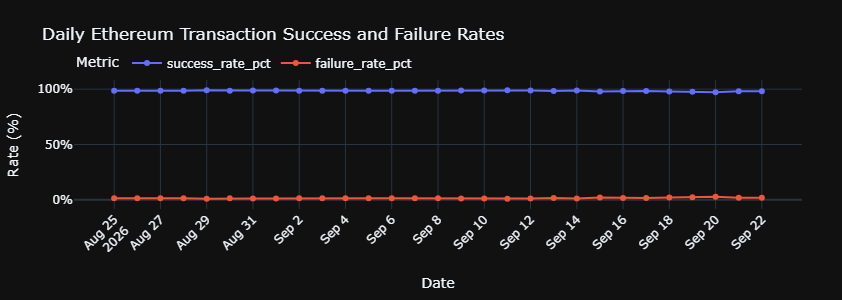

In [126]:
import plotly.express as px

fig = px.line(
    complete_days,
    x="date",
    y=["success_rate_pct", "failure_rate_pct"],
    markers=True,
    title="Daily Ethereum Transaction Success and Failure Rates",
    labels={
        "date": "Date",
        "value": "Rate (%)",
        "variable": "Metric"
    },
    template="plotly_dark"
)

fig.update_layout(
    hovermode="x unified",
    height=300,
    margin=dict(l=60, r=40, t=80, b=80),
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=0
    ),
    xaxis=dict(
        tickangle=-45,
        nticks=20
    ),
    yaxis=dict(
        ticksuffix="%",
        title="Rate (%)"
    )
)

fig.update_traces(
    marker=dict(size=6),
    hovertemplate="%{y:.2f}%<extra></extra>"
)

fig.update_xaxes(
    fixedrange=False  # Allow zooming and panning along the x-axis
)

fig.update_yaxes(
    fixedrange=True  # Prevent zooming and panning along the y-axis
)

fig.show()

## Visualization - Daily Failed Transactions

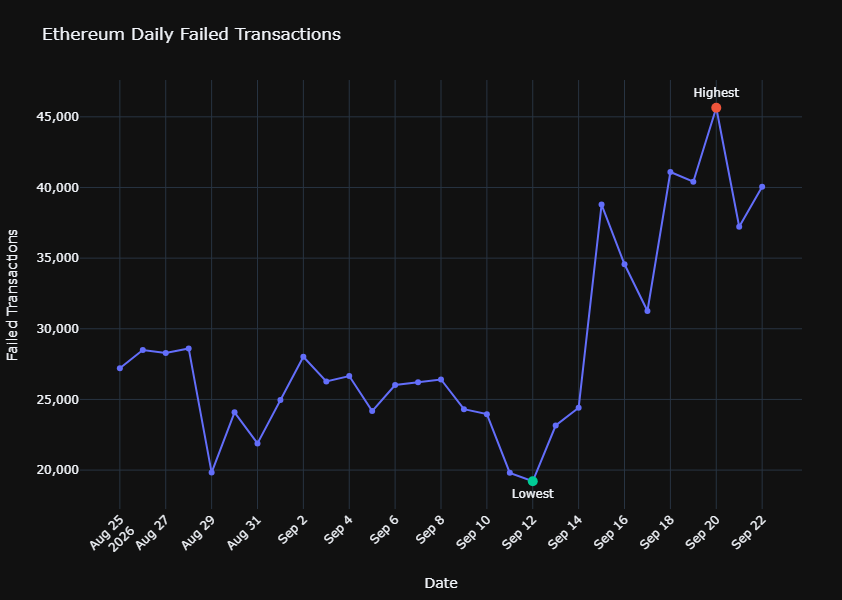

In [137]:
fig = px.line(
    complete_days,
    x="date",
    y="failed_transactions",
    markers=True,
    title="Ethereum Daily Failed Transactions",
    labels={
        "date": "Date",
        "failed_transactions": "Failed Transactions"
    },
    template="plotly_dark"
)

fig.update_traces(
    marker=dict(size=6),
    hovertemplate="%{y:,.0f}<extra></extra>"
)

# Highest and lowest days
highest_failed_tx = complete_days.loc[
    complete_days["failed_transactions"].idxmax()
]

lowest_failed_tx = complete_days.loc[
    complete_days["failed_transactions"].idxmin()
]

fig.add_scatter(
    x=[highest_failed_tx["date"]],
    y=[highest_failed_tx["failed_transactions"]],
    mode="markers+text",
    text=["Highest"],
    textposition="top center",
    marker=dict(size=10),
    name="Highest",
    hovertemplate=(
        "%{x|%b %d, %Y}<br>"
        "Failed transactions: %{y:,.0f}"
        "<extra></extra>"
    ),
    showlegend=False
)

fig.add_scatter(
    x=[lowest_failed_tx["date"]],
    y=[lowest_failed_tx["failed_transactions"]],
    mode="markers+text",
    text=["Lowest"],
    textposition="bottom center",
    marker=dict(size=10),
    name="Lowest",
    hovertemplate=(
        "%{x|%b %d, %Y}<br>"
        "Failed transactions: %{y:,.0f}"
        "<extra></extra>"
    ),
    showlegend=False
)


fig.update_layout(
    hovermode="x unified",
    height=600,
    margin=dict(l=60, r=40, t=80, b=80),
    xaxis=dict(
        tickangle=-45,
        nticks=20,
        rangeslider=dict(visible=False)
    ),
    yaxis=dict(
        tickformat=","
    )
)

fig.update_xaxes(
    fixedrange=False  # Allow zooming and panning along the x-axis
)

fig.update_yaxes(
    fixedrange=True  # Prevent zooming and panning along the y-axis
)

fig.show()

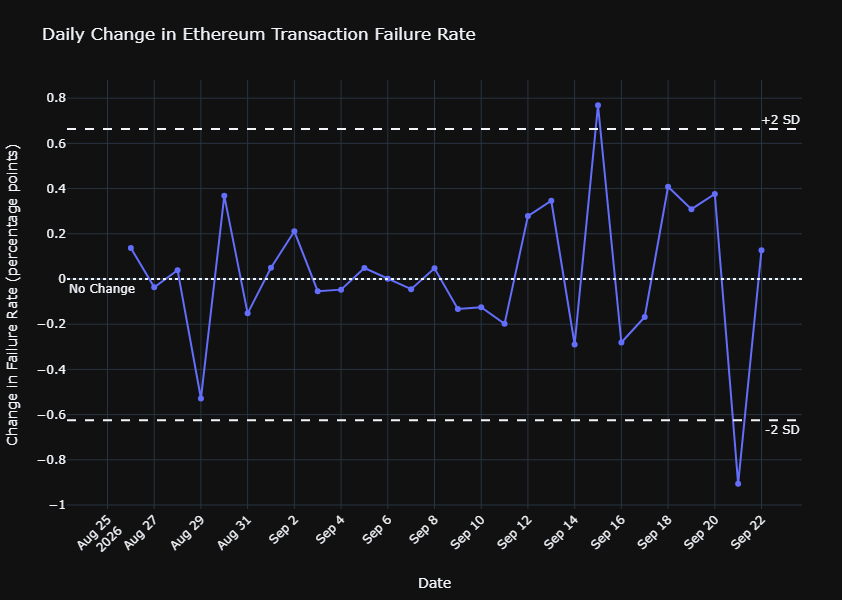

In [111]:
import plotly.express as px

fig = px.line(
    complete_days,
    x="date",
    y="failure_rate_change_pp",
    markers=True,
    title="Daily Change in Ethereum Transaction Failure Rate",
    labels={
        "date": "Date",
        "failure_rate_change_pp": "Change in Failure Rate (pp)"
    },
    template="plotly_dark"
)

# Add anomaly thresholds
fig.add_hline(
    y=upper_threshold,
    line_dash="dash",
    annotation_text="+2 SD",
    annotation_position="top right"
)

fig.add_hline(
    y=lower_threshold,
    line_dash="dash",
    annotation_text="-2 SD",
    annotation_position="bottom right"
)

# Add zero reference line
fig.add_hline(
    y=0,
    line_dash="dot",
    annotation_text="No Change",
    annotation_position="bottom left"
)

fig.update_layout(
    hovermode="x unified",
    height=600,
    margin=dict(l=60, r=40, t=80, b=80),
    xaxis=dict(
        tickangle=-45,
        nticks=20
    ),
    yaxis=dict(
        title="Change in Failure Rate (percentage points)"
    )
)

fig.update_traces(
    marker=dict(size=6),
    hovertemplate="%{y:.3f} pp<extra></extra>"
)

fig.update_xaxes(
    fixedrange=False
)

fig.update_yaxes(
    fixedrange=True
)


fig.show()

## Finding | Evidence | Meaning

### Finding

Ethereum transaction execution was **predominantly successful** during the **29 complete days** analyzed, with an overall success rate of **98.49%** compared with a **1.51% failure rate**. The partial first and last calendar days were excluded dynamically before calculating the period-level metrics.

### Evidence

* 55,151,035 transactions were recorded across the 29 complete days.
* 54,319,998 transactions succeeded.
* 831,037 transactions failed.
* Overall success rate was **98.49%**.
* Overall failure rate was **1.51%**.
* Daily failure rate ranged from **0.94%** to **2.69%** across the complete days.
* The largest detected day-over-day changes were approximately **+0.77 percentage points** and **−0.90 percentage points**.

### Meaning

Successful transaction execution was the dominant outcome throughout the complete-day analysis period. Daily failure rates varied, with some higher-failure days, but the analysis does not establish the cause of those changes.


## Limitations

- The analysis covers a **30-day period**, so the observed transaction success and failure patterns do not establish longer-term trends.

- The **first and last calendar dates are partial days** because the analysis window does not align exactly with calendar-day boundaries. These dates were excluded from the comparable daily analysis.

- **Transaction failure rate measures the proportion of transactions that did not successfully execute.** It does not indicate the specific reason why a transaction failed.

- The **anomaly screen identifies unusually large day-to-day changes in failure rate**, but it does not establish what caused those changes.

- The analysis identifies **patterns in transaction success and failure but does not establish their underlying causes**. Additional investigation would be required to determine why failure activity increased or decreased on particular days.